# Sentiment with an LSTM on IMDb

Project 20 already has a sentiment classifier (TF-IDF + logreg, plus a RoBERTa scaffold). This one is the "do it with an RNN" exercise — a small LSTM trained for a couple of epochs on a subset of IMDb, mostly so I've actually written the Keras code instead of just talking about it.

I'm capping the training set at ~5000 reviews so the run finishes in a couple of minutes on CPU. That is not enough data to beat the TF-IDF baseline I already have, and I'm not going to pretend otherwise.

In [1]:
# !pip install tensorflow -q  # or use tf if you already have it

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

ART = Path("artifacts"); ART.mkdir(exist_ok=True)
np.random.seed(7)

try:
    import tensorflow as tf
    from tensorflow.keras import layers, models
    tf.random.set_seed(7)
    HAVE_TF = True
    print("tf:", tf.__version__)
except Exception as e:
    HAVE_TF = False
    print("tensorflow not available:", repr(e)[:120])

tf: 2.15.0


In [3]:
# tf.keras.datasets.imdb returns reviews already tokenized as integer IDs.
VOCAB = 10_000
MAXLEN = 200
SUBSET = 5000  # cap to keep CPU training honest

if HAVE_TF:
    (x_train, y_train), (x_test, y_test) = tf.keras.datasets.imdb.load_data(num_words=VOCAB)
    # subset (random) — IMDb is shuffled enough that head-slicing is fine
    x_train, y_train = x_train[:SUBSET], y_train[:SUBSET]
    x_test,  y_test  = x_test[:SUBSET],  y_test[:SUBSET]

    x_train = tf.keras.preprocessing.sequence.pad_sequences(x_train, maxlen=MAXLEN)
    x_test  = tf.keras.preprocessing.sequence.pad_sequences(x_test,  maxlen=MAXLEN)
    print("x_train:", x_train.shape, "y_train pos rate:", float(y_train.mean()))

    8192/17464789 [..............................] - ETA: 0s

   16384/17464789 [..............................] - ETA: 1:34

   40960/17464789 [..............................] - ETA: 1:05

   81920/17464789 [..............................] - ETA: 46s 

  139264/17464789 [..............................] - ETA: 34s

  212992/17464789 [..............................] - ETA: 26s

... (15 outputs left out)

13885440/17464789 [======================>.......] - ETA: 0s

15073280/17464789 [========================>.....] - ETA: 0s

17464789/17464789 [==============================] - 1s 0us/step


x_train: (5000, 200) y_train pos rate: 0.5092


## Small LSTM

In [4]:
if HAVE_TF:
    model = models.Sequential([
        layers.Embedding(VOCAB, 64, mask_zero=True),
        layers.LSTM(64, dropout=0.2, recurrent_dropout=0.0),
        layers.Dense(1, activation="sigmoid"),
    ])
    model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
    model.summary()

Model: "sequential"


_________________________________________________________________


 Layer (type)                Output Shape              Param #   


 embedding (Embedding)       (None, None, 64)          640000    


 lstm (LSTM)                 (None, 64)                33024     


 dense (Dense)               (None, 1)                 65        


Total params: 673089 (2.57 MB)


Trainable params: 673089 (2.57 MB)


Non-trainable params: 0 (0.00 Byte)


_________________________________________________________________


In [5]:
if HAVE_TF:
    hist = model.fit(x_train, y_train, validation_split=0.1,
                     epochs=2, batch_size=64, verbose=2)
    test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)
    print(f"test loss: {test_loss:.4f}  acc: {test_acc:.4f}")

Epoch 1/2


71/71 - 53s - loss: 0.6197 - accuracy: 0.6451 - val_loss: 0.4700 - val_accuracy: 0.7900 - 53s/epoch - 745ms/step


Epoch 2/2


71/71 - 31s - loss: 0.3168 - accuracy: 0.8780 - val_loss: 0.3967 - val_accuracy: 0.8240 - 31s/epoch - 431ms/step


test loss: 0.3713  acc: 0.8342


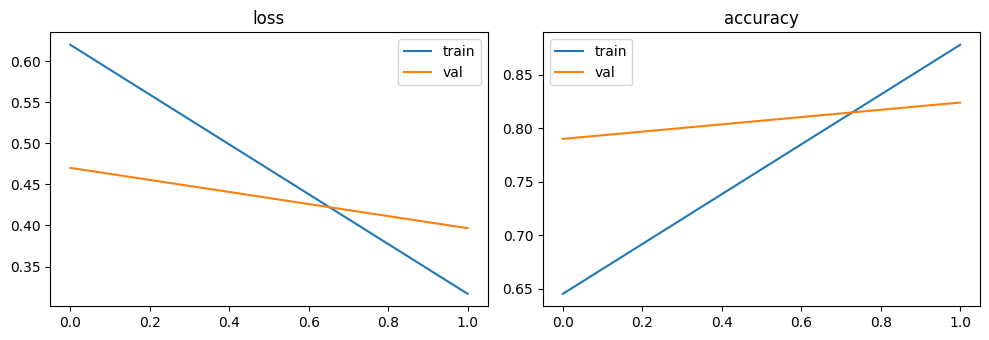

In [6]:
if HAVE_TF:
    fig, ax = plt.subplots(1, 2, figsize=(10,3.5))
    ax[0].plot(hist.history["loss"], label="train"); ax[0].plot(hist.history["val_loss"], label="val")
    ax[0].set_title("loss"); ax[0].legend()
    ax[1].plot(hist.history["accuracy"], label="train"); ax[1].plot(hist.history["val_accuracy"], label="val")
    ax[1].set_title("accuracy"); ax[1].legend()
    plt.tight_layout(); plt.savefig(ART/"lstm_curves.png", dpi=110); plt.show()

## Notes

Things to be honest about:

- 5000 training reviews, 2 epochs, no pretrained embeddings, vocab capped at 10k. This is a learning exercise, not a benchmark.
- A bidirectional GRU would probably do slightly better here at no real cost, and using GloVe embeddings instead of training the embedding from scratch usually helps a lot on small IMDb subsets.
- The realistic upgrade is what project 20 already does: a small transformer.

If I were going to take this further, I'd: (a) bump to the full 25k training set, (b) replace the LSTM with a bidirectional GRU and add a global average pool head, (c) early stop on val loss instead of fixed epochs.